# Time-domain science in the LSST era

A dedicated spectroscopic array is most valuable where the bottleneck is telescope time on single
targets: transient classification, rapid multi-messenger response and high-cadence monitoring.
This notebook asks what magnitude and distance limits the nominal 20-telescope array reaches, and
how they move at 10 m and 30 m equivalent.

Assumptions:

* Classification: SNR 5 per R = 300 bin over 450 to 650 nm (SEDM-like, Blagorodnova et al.
  2018), which is SNR 2.04 per native resel; magnitudes in R (Cousins, close to SDSS r).
* Kilonova: AT2017gfo-like, r = 17.3 at 0.5 d at 40 Mpc, fading 0.95 mag per day in r, cooling
  10,000 K to 5000 K to 2500 K at 0.5, 1.5 and 5.5 d (Drout et al. 2017; Shappee et al. 2017).
* SN Ia: $M_B$ = -19.3 at peak, a 6000 K blackbody, no K-correction; luminosity distance from a
  flat $\Lambda$CDM with $H_0$ = 70, $\Omega_m$ = 0.3.
* TDE: 20,000 K blackbody; monitoring needs SNR 20 per R = 300 bin.
* AGN reverberation: 5100 A continuum precision per epoch from the SNR per resel co-added over a
  50 A window, photon noise only. Fiber spectrophotometric stability is not modelled.
* Sky: the bundled grey-time table (moon up). Dark time is 0.3 to 0.5 mag deeper at the faint end.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis
try:
    plt.style.use('gks')      # the author's matplotlib style; skipped if you do not have it
except OSError:
    pass

In [2]:
# ---- knobs: array sizes compared throughout (replicated in arrays of 20) ----
from pathlib import Path
SCALES = {20: "nominal 20x (3.2 m eq.)", 200: "10 arrays (10.3 m eq.)", 1720: "86 arrays (30.1 m eq.)"}
NS = np.array([20, 40, 60, 100, 200, 400, 600, 1000, 1720, 2500])
FIG = Path("../memo/figures")          # memo figures land here if the directory exists
def save(fig, name):
    if FIG.is_dir():
        fig.savefig(FIG / name)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 10, "legend.fontsize": 9})
def tel(n, telescopes_per_input=20):
    return Telescope(n_telescopes=int(n), fiber="18um", combine="fiber", telescopes_per_input=telescopes_per_input)
def mark_scales(ax):
    for n in (20, 200, 1720):
        ax.axvline(n, color='0.6', ls='--', lw=0.8)
    ax.set_xscale('log'); ax.set_xlabel("Number of telescopes")
    equivalent_diameter_axis(ax, ticks=(3, 5, 10, 20, 30))

In [3]:
WINDOW = (450, 650); R_BIN = 300; SNR_CLASS = 5; BAND = "R"
def bench(n):
    return LFASTETC("bench_r1800", telescope=tel(n), wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
k = 1800/R_BIN
snr_resel_class = SNR_CLASS/np.sqrt(k)
sn_like = Source.blackbody(6000, 0, BAND)

## Classification depth versus array size

The dotted horizontal lines are the single-visit depths of ZTF and LSST in r. A classifier that
cannot reach the survey's own discovery depth leaves the faintest transients unclassified, so the
distance between the curves and the LSST line is the number to watch.

  300 s: N=20: R<19.5  N=200: R<20.8  N=1720: R<22.0
 1800 s: N=20: R<20.8  N=200: R<22.1  N=1720: R<23.3
 3600 s: N=20: R<21.3  N=200: R<22.5  N=1720: R<23.7


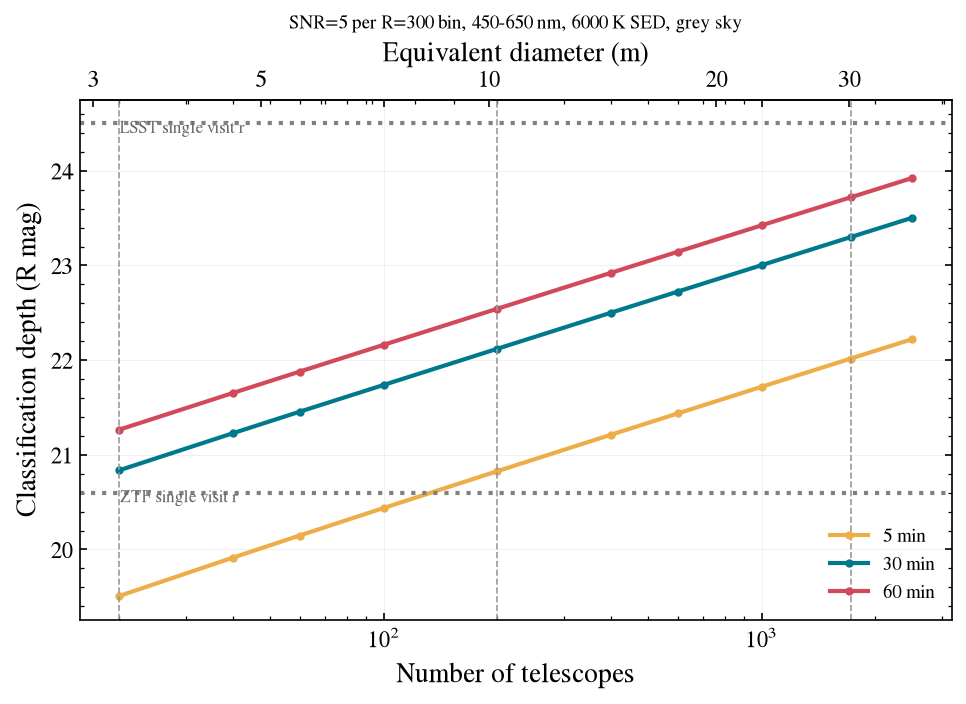

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
depth = {}
for exp, color in ((300, 'C2'), (1800, 'C0'), (3600, 'C1')):
    d = np.array([bench(int(n)).limiting_magnitude(sn_like, exp, snr_resel_class, wavelength=WINDOW) for n in NS])
    depth[exp] = dict(zip(NS, d))
    ax.plot(NS, d, marker='o', ms=3, color=color, label=f"{exp/60:.0f} min")
for mag, txt in ((20.6, "ZTF single visit r"), (24.5, "LSST single visit r")):
    ax.axhline(mag, color='0.5', ls=':'); ax.text(NS[0], mag-0.1, txt, fontsize=8, color='0.4')
ax.set_ylabel("Classification depth (R mag)")
ax.set_title("SNR=5 per R=300 bin, 450-650 nm, 6000 K SED, grey sky", fontsize=9); ax.legend()
mark_scales(ax)
save(fig, "classification_depth_vs_N.pdf")
for exp, d in depth.items():
    print(f"{exp:5d} s: " + "  ".join(f"N={n}: R<{d[n]:.1f}" for n in (20, 200, 1720)))

## Kilonova horizon

Distance at which an AT2017gfo-like kilonova can still be classified in a 30 minute exposure at
0.5, 1, 2 and 3 days after merger, versus the array size. The shaded bands are the LIGO
binary-neutron-star ranges: 150 to 170 Mpc in O4 and 225 to 295 Mpc planned for O5 (LVK observing
plan G2002127-v37, Oct 2026).

day 0.5: N=20:   228 Mpc  N=200:   411 Mpc  N=1720:   708 Mpc
day 1: N=20:   174 Mpc  N=200:   314 Mpc  N=1720:   540 Mpc
day 2: N=20:    97 Mpc  N=200:   175 Mpc  N=1720:   301 Mpc
day 3: N=20:    58 Mpc  N=200:   105 Mpc  N=1720:   182 Mpc


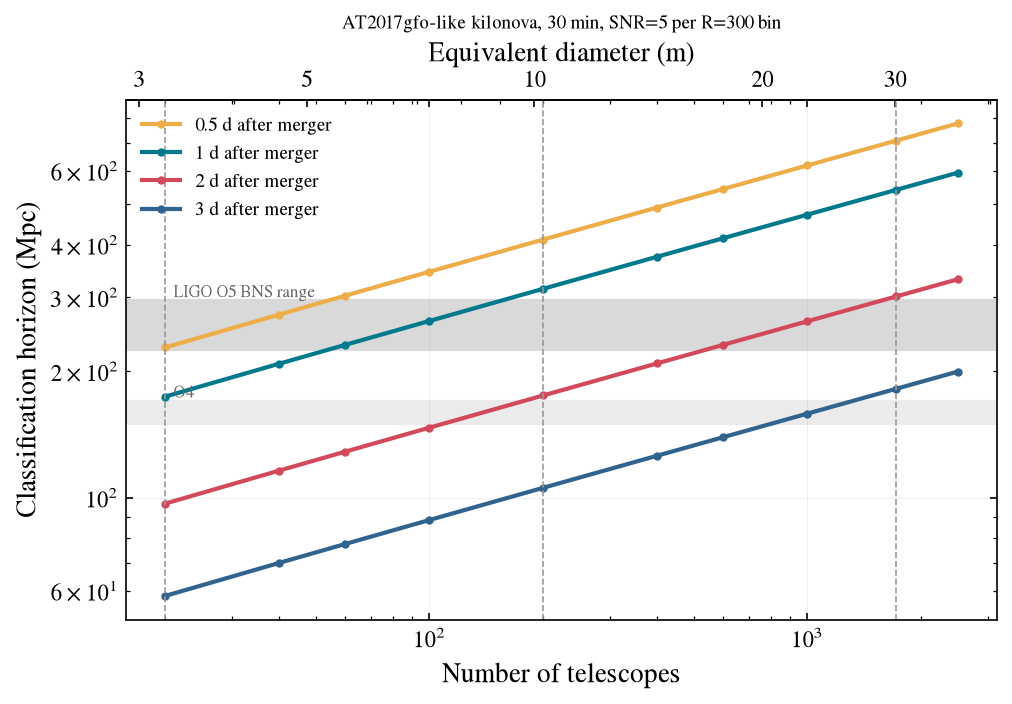

In [5]:
def kn_src(day):
    teff = np.interp(day, [0.5, 1.5, 5.5], [10000, 5000, 2500])
    return Source.blackbody(teff, 0, BAND)
def kn_mag_40(day):
    return 17.3 + 0.95*(day-0.5)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
horizon = {}
for day, color in ((0.5, 'C2'), (1, 'C0'), (2, 'C1'), (3, 'C3')):
    lim = np.array([bench(int(n)).limiting_magnitude(kn_src(day), 1800, snr_resel_class, wavelength=WINDOW) for n in NS])
    D = 40*10**((lim - kn_mag_40(day))/5)
    horizon[day] = dict(zip(NS, D))
    ax.plot(NS, D, marker='o', ms=3, color=color, label=f"{day} d after merger")
ax.axhspan(225, 295, color='0.85', zorder=0); ax.text(NS[0]*1.05, 300, "LIGO O5 BNS range", fontsize=8, color='0.4')
ax.axhspan(150, 170, color='0.92', zorder=0); ax.text(NS[0]*1.05, 173, "O4", fontsize=8, color='0.4')
ax.set_yscale('log'); ax.set_ylabel("Classification horizon (Mpc)")
ax.set_title("AT2017gfo-like kilonova, 30 min, SNR=5 per R=300 bin", fontsize=9); ax.legend()
mark_scales(ax)
save(fig, "kilonova_horizon_vs_N.pdf")
for day, d in horizon.items():
    print(f"day {day}: " + "  ".join(f"N={n}: {d[n]:5.0f} Mpc" for n in (20, 200, 1720)))

## SN Ia classification redshift reach

Maximum redshift at which a SN Ia can be classified at peak (solid) and one magnitude past peak
(dashed). B is taken equal to R for the 6000 K SED and the K-correction is ignored, so treat the
redshifts beyond about 0.3 as indicative.

 1800 s at peak: N=20: z<0.22  N=200: z<0.36  N=1720: z<0.57
 3600 s at peak: N=20: z<0.26  N=200: z<0.43  N=1720: z<0.67


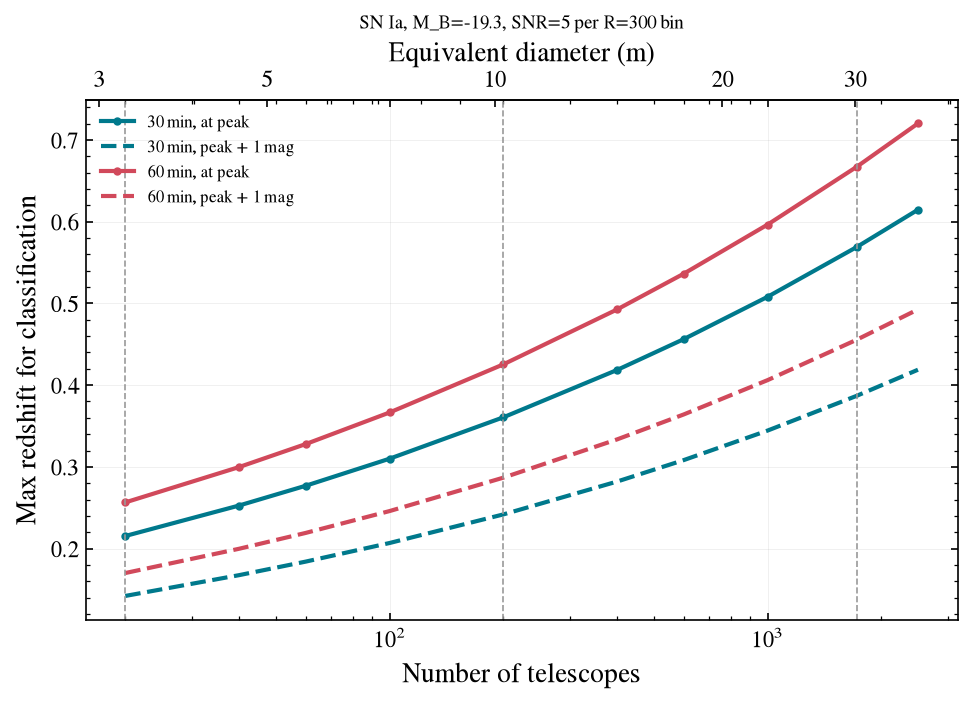

In [6]:
from astropy.cosmology import FlatLambdaCDM
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
zs = np.linspace(0.01, 1.2, 600)
m_peak = -19.3 + cosmo.distmod(zs).value
fig, ax = plt.subplots(figsize=(7.5, 4.5))
zreach = {}
for exp, color in ((1800, 'C0'), (3600, 'C1')):
    zr = []
    for n in NS:
        lim = bench(int(n)).limiting_magnitude(sn_like, exp, snr_resel_class, wavelength=WINDOW)
        zr.append((np.interp(lim, m_peak, zs), np.interp(lim - 1, m_peak, zs)))
    zr = np.array(zr); zreach[exp] = dict(zip(NS, zr[:, 0]))
    ax.plot(NS, zr[:, 0], marker='o', ms=3, color=color, label=f"{exp/60:.0f} min, at peak")
    ax.plot(NS, zr[:, 1], ls='--', color=color, label=f"{exp/60:.0f} min, peak + 1 mag")
ax.set_ylabel("Max redshift for classification")
ax.set_title("SN Ia, M_B=-19.3, SNR=5 per R=300 bin", fontsize=9); ax.legend(fontsize=8)
mark_scales(ax)
save(fig, "snia_zreach_vs_N.pdf")
for exp, d in zreach.items():
    print(f"{exp:5d} s at peak: " + "  ".join(f"N={n}: z<{d[n]:.2f}" for n in (20, 200, 1720)))

## TDE monitoring

Tidal disruption events stay bright and blue (about 20,000 K) for months. Weekly spectra with
SNR 20 per R = 300 bin follow the line evolution. Time per epoch for TDEs at R = 17 to 20.

In [7]:
tde = Source.blackbody(20000, 0, BAND)
snr_resel_mon = 20/np.sqrt(k)
for n in (20, 200, 1720):
    t = bench(n).exptime_vs_mag(tde, [17, 18, 19, 20], snr=snr_resel_mon, wavelength=WINDOW)
    print(f"N={n:5d}: " + "  ".join(f"R={m}: {ti/60:6.1f} min" for m, ti in zip((17, 18, 19, 20), t)))

N=   20: R=17:    1.6 min  R=18:    4.5 min  R=19:   14.2 min  R=20:   55.9 min
N=  200: R=17:    0.3 min  R=18:    0.9 min  R=19:    2.6 min  R=20:    8.0 min
N= 1720: R=17:    0.1 min  R=18:    0.3 min  R=19:    0.7 min  R=20:    1.9 min


## AGN reverberation mapping: continuum precision per epoch

Reverberation campaigns need nightly spectrophotometry at the 1 to 2% level over months. The
table gives the photon-noise precision on the 5100 A continuum (50 A window) per 10 minute epoch
for Seyferts at V = 14 to 17. The fiber-aperture and spectrophotometric stability floor is not
included, and it is the real question for this programme.

In [8]:
agn = Source.powerlaw(-0.5, 0, "V", system="AB")
WIN_A = 50; CENTER_NM = 510.0                               # the "50 A window at 5100 A"
lo, hi = CENTER_NM - WIN_A/20, CENTER_NM + WIN_A/20          # 10 A per nm, half-width each side
for n in (20, 200, 1720):
    e = LFASTETC("bench_r1800", telescope=tel(n))
    row = []
    for m in (14, 15, 16, 17):
        r = e.snr(agn.with_mag(m), 600)
        win = (r.wavelength >= lo) & (r.wavelength <= hi)
        # information sum over the resels: the SNR of one common amplitude fitted against the
        # known continuum shape, (sum_i SNR_i^2)^(1/2); not the SNR of an unweighted flux sum
        snr50 = np.sqrt(np.nansum(r.snr[win]**2))
        row.append(f"V={m}: {100/snr50:.2f}%")
    print(f"N={n:5d} (10 min): " + "  ".join(row))

N=   20 (10 min): V=14: 0.23%  V=15: 0.37%  V=16: 0.61%  V=17: 1.04%
N=  200 (10 min): V=14: 0.07%  V=15: 0.12%  V=16: 0.19%  V=17: 0.33%
N= 1720 (10 min): V=14: 0.03%  V=15: 0.04%  V=16: 0.07%  V=17: 0.11%
